# **EDA: Banque de CV**
cette étape permet d'analyser les documents avant de réaliser le pipeline.


In [31]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import pymupdf
from docx import Document
from pptx import Presentation
from pptx.enum.shapes import MSO_SHAPE_TYPE

In [32]:
#recupérer tous les files des cv dans le dossier banque de CVs
cv_files = list(Path("Banque de CVs").rglob("*.pdf"))
cv_files += list(Path("Banque de CVs").rglob("*.docx"))
cv_files += list(Path("Banque de CVs").rglob("*.pptx"))

print("nombre de CV:", len(cv_files))
for file in cv_files:
    print(file.name)

nombre de CV: 10
CV_Jean_MarcRuissot_2023.pdf
CV_Luc_Besnier.pdf
CV_MARTIN_DUPONT.pdf
CV_Pierre_Maturet.pdf
CV_Aramis_Kahn.docx
CV_Charles_McTurland.docx
CV_Aziz_de_la_court.pptx
CV_Jeanne_Ferdinand.pptx
CV_Matthieu_Dufour.pptx
CV_Nicolas_Pascal.pptx


# **Extraction exploratoire**

In [40]:
#extraire le texte
#pdf: pymupdf permet de lire le texte des pages pdf
def lire_pdf(path):
    with pymupdf.open(path) as pdf:
        texte=[]
        nombre_imgs=0
        nombre_tables=0
        nombre_liens = 0
        for page in pdf:
            texte.append(page.get_text())
            nombre_imgs+= len(page.get_images(full=True))
            nombre_tables+= len(page.find_tables().tables)
            nombre_liens+= sum(1 for lien in page.get_links() if lien.get("uri"))

        texte= "\n".join(texte)
        return texte,len(pdf),nombre_imgs,nombre_tables,nombre_liens

#docx: python-docx donne accès au XML word et réalise
#la recherche des éléments w:t inclut certaines zones de texte ignorées par doc.paragraphs
w="{http://schemas.openxmlformats.org/wordprocessingml/2006/main}"
def lire_docx(path):
    doc=Document(path)
    lignes=[]
    for p in doc.element.body.iter(f"{w}p"):
        ligne= "".join(t.text or "" for t in p.iter(f"{w}t")).strip()
        if ligne and ligne not in lignes[-1:]:
            lignes.append(ligne)
    nombre_tables=len(doc.tables)
    nombre_imgs=len(doc.inline_shapes)
    nombre_liens = len(list(doc.element.body.iter(f"{w}hyperlink")))
    return "\n".join(lignes),None,nombre_imgs,nombre_tables,nombre_liens

#pptx: python-pptx lit les zones de texte,tableaux et formes groupées
def lire_pptx(path):
    pptx=Presentation(path)
    textes=[]
    nombre_imgs=0
    nombre_tables=0
    nombre_liens = 0
    for slide in pptx.slides:
        formes= list(slide.shapes)
        while formes:
            forme=formes.pop()
            if forme.shape_type == MSO_SHAPE_TYPE.GROUP:
                formes.extend(forme.shapes)
            elif forme.has_table:
                nombre_tables+=1
                for ligne in forme.table.rows:
                    textes.append(" | ".join(cell.text for cell in ligne.cells))
            elif forme.shape_type == MSO_SHAPE_TYPE.PICTURE:
                nombre_imgs+=1
            elif forme.has_text_frame:
                textes.append(forme.text)
                for p in forme.text_frame.paragraphs:
                    for run in p.runs:
                        if run.hyperlink.address:
                            nombre_liens+=1
            if forme.shape_type != MSO_SHAPE_TYPE.GROUP:
                if forme.click_action.hyperlink.address:
                    nombre_liens += 1
    return "\n".join(textes),len(pptx.slides),nombre_imgs,nombre_tables,nombre_liens

#lire tous les cv
def lire_cv(path):
    cv= {".pdf":lire_pdf,".docx":lire_docx,".pptx":lire_pptx}
    return cv[path.suffix.lower()](path)

# **Tableau EDA**

In [41]:
results=[]
texts={}
for file in cv_files:
    text,pages,nombre_imgs,nombre_tables,nombre_liens = lire_cv(file)
    nombre_caracteres=len(text.strip())
    texts[file.name]=text

    results.append({"fichier":file.name,"format":file.suffix.lower(),
                    "taille_ko":round(file.stat().st_size /1024,1),"pages_slides": pages,
                    "caracteres": nombre_caracteres,"nombre_tableaux":nombre_tables,
                    "nombre_images": nombre_imgs,"nombre_liens": nombre_liens,"a_verifier": nombre_caracteres<500})
df=pd.DataFrame(results)
display(df)

,fichier,format,taille_ko,pages_slides,caracteres,nombre_tableaux,nombre_images,nombre_liens,a_verifier
0,CV_Jean_MarcRuissot_2023.pdf,.pdf,214.0,1.0,3046,0,14,29,False
1,CV_Luc_Besnier.pdf,.pdf,188.7,1.0,2247,0,0,3,False
2,CV_MARTIN_DUPONT.pdf,.pdf,200.6,1.0,4629,0,6,0,False
3,CV_Pierre_Maturet.pdf,.pdf,144.4,1.0,3035,0,7,0,False
4,CV_Aramis_Kahn.docx,.docx,28.6,NaN,2914,2,0,0,False
5,CV_Charles_McTurland.docx,.docx,431.0,NaN,296,0,0,4,True
6,CV_Aziz_de_la_court.pptx,.pptx,70.0,1.0,2777,0,0,0,False
7,CV_Jeanne_Ferdinand.pptx,.pptx,68.2,1.0,2941,0,0,0,False
8,CV_Matthieu_Dufour.pptx,.pptx,256.3,1.0,2577,0,4,0,False
9,CV_Nicolas_Pascal.pptx,.pptx,110.2,1.0,2723,0,2,0,False


CV de Charles McTurland présente une extraction textuelle incomplète avec 296 caractères, malgré la présence de nombreuses informations dans le doc. Cela met en évidence les limites de l'extraction classique avec python-docx. Donc, par la suite, il faut ajouter une méthode complémentaire d'OCR pour récupérer les informations manquantes.

In [13]:
import sys
from pathlib import Path

# Ajouter le dossier parent (test) au chemin Python
projet = Path.cwd().resolve().parent

if str(projet) not in sys.path:
    sys.path.insert(0, str(projet))

In [14]:
from pathlib import Path
import pandas as pd

from app.extraction import analyse_cv, lire_docx, lire_pdf, lire_pptx
from app.ocr import images_utiles, ocr_images, ocr_complet

In [15]:
cv = Path("Banque de CVs/WORD/CV_Charles_McTurland.docx")

texte_natif, liens = lire_docx(cv)

print("Caractères natifs :", len(texte_natif.strip()))
print("Liens :", liens)

print("\n--- TEXTE NATIF ---")
print(texte_natif)

Caractères natifs : 75
Liens : ['mailto:cmcturland@email.com', 'https://www.linkedin.com/', 'mailto:cmcturland@email.com', 'https://www.linkedin.com/']

--- TEXTE NATIF ---
cmcturland@email.com
(123) 456-7890
New York, NY LinkedIn
Charles McTurland


Image : 0
Dimensions : (250, 420)
Mode : RGBA


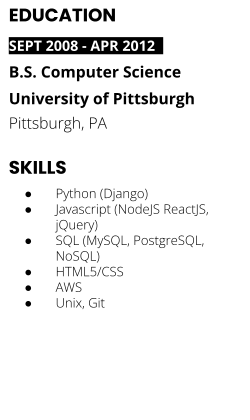

Image : 1
Dimensions : (524, 142)
Mode : RGB


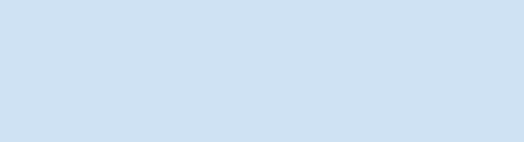

Image : 2
Dimensions : (535, 746)
Mode : RGBA


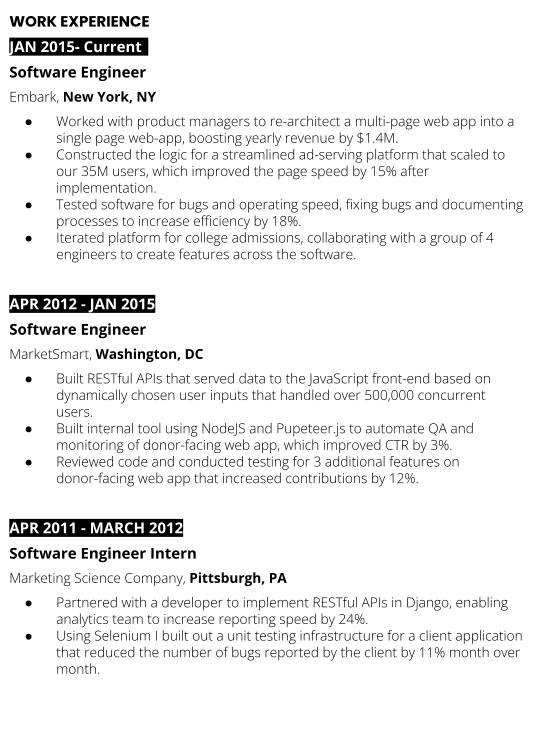

Image : 3
Dimensions : (536, 145)
Mode : RGBA


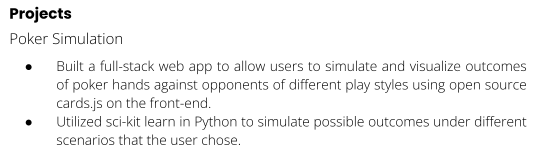

In [16]:
from PIL import Image
from io import BytesIO
from IPython.display import display

blobs = images_utiles(cv, ".docx")

for i, blob in enumerate(blobs):
    image = Image.open(BytesIO(blob))

    print("Image :", i)
    print("Dimensions :", image.size)
    print("Mode :", image.mode)

    display(image)

In [17]:
from io import BytesIO
from PIL import Image
from app.ocr import ocr_image

for i, blob in enumerate(blobs):
    with Image.open(BytesIO(blob)) as image:
        texte = ocr_image(image)

    print(f"\n--- IMAGE {i} ---")
    print("Caractères OCR :", len(texte))
    print(texte[:1500])


--- IMAGE 0 ---
Caractères OCR : 193
EDUCATION
B.S. Computer Science

University of Pittsburgh
Pittsburgh, PA

SKILLS

Python (Django)

Javascript (NodeJS React|S,
jQuery)

SQL (MySQL, PostgreSQL,
NoSQL)

HTML5/CSS

AWS

Unix, Git

--- IMAGE 1 ---
Caractères OCR : 0


--- IMAGE 2 ---
Caractères OCR : 1441
WORK EXPERIENCE

AN 2015- Current

Software Engineer
Embark, New York, NY

Worked with product managers to re-architect a multi-page web app into a
single page web-app, boosting yearly revenue by $1.4M.

Constructed the logic for a streamlined ad-serving platform that scaled to
our 35M users, which improved the page speed by 15% after
implementation.

Tested software for bugs and operating speed, fixing bugs and documenting
processes to increase efficiency by 18%.

Iterated platform for college admissions, collaborating with a group of 4
engineers to create features across the software.

APR 2012 - JAN 2015
Software Engineer
MarketSmart, Washington, DC

Built RESTful APIs that served

In [18]:
import pytesseract
pytesseract.pytesseract.tesseract_cmd = (
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

In [19]:
texte_ocr_complet = ocr_complet(cv, cv.suffix.lower())

print("Caractères OCR complet :", len(texte_ocr_complet))
print(texte_ocr_complet)

Caractères OCR complet : 1960
EDUCATION
B.S. Computer Science

University of Pittsburgh
Pittsburgh, PA

SKILLS

Python (Django)

Javascript (NodeJS React|S,
jQuery)

SQL (MySQL, PostgreSQL,
NoSQL)

HTML5/CSS

AWS

Unix, Git
WORK EXPERIENCE

AN 2015- Current

Software Engineer
Embark, New York, NY

Worked with product managers to re-architect a multi-page web app into a
single page web-app, boosting yearly revenue by $1.4M.

Constructed the logic for a streamlined ad-serving platform that scaled to
our 35M users, which improved the page speed by 15% after
implementation.

Tested software for bugs and operating speed, fixing bugs and documenting
processes to increase efficiency by 18%.

Iterated platform for college admissions, collaborating with a group of 4
engineers to create features across the software.

APR 2012 - JAN 2015
Software Engineer
MarketSmart, Washington, DC

Built RESTful APIs that served data to the JavaScript front-end based on
dynamically chosen user inputs that handl

In [20]:
resultat = analyse_cv(cv)

print("Catégorie :", resultat.categorie)
print("Caractères natifs :", resultat.caracteres_natifs)
print("Nombre d'images :", resultat.nb_images)
print("Caractères OCR :", resultat.caracteres_ocr)
print("Caractères finaux :", len(resultat.texte))

print("\n--- TEXTE FINAL ---")
print(resultat.texte)

Catégorie : ocr_complet
Caractères natifs : 75
Nombre d'images : 4
Caractères OCR : 1960
Caractères finaux : 2134

--- TEXTE FINAL ---
cmcturland@email.com
(123) 456-7890
New York, NY LinkedIn
Charles McTurland

complément OCR :
EDUCATION
B.S. Computer Science

University of Pittsburgh
Pittsburgh, PA

SKILLS

Python (Django)

Javascript (NodeJS React|S,
jQuery)

SQL (MySQL, PostgreSQL,
NoSQL)

HTML5/CSS

AWS

Unix, Git
WORK EXPERIENCE

AN 2015- Current

Software Engineer
Embark, New York, NY

Worked with product managers to re-architect a multi-page web app into a
single page web-app, boosting yearly revenue by $1.4M.

Constructed the logic for a streamlined ad-serving platform that scaled to
our 35M users, which improved the page speed by 15% after
implementation.

Tested software for bugs and operating speed, fixing bugs and documenting
processes to increase efficiency by 18%.

Iterated platform for college admissions, collaborating with a group of 4
engineers to create features acro

In [8]:
dossier = Path("Banque de CVs")

cv_files = [
    fichier
    for fichier in dossier.rglob("*")
    if fichier.suffix.lower() in [".pdf", ".docx", ".pptx"]
]

resultats = []

for fichier in cv_files:
    try:
        resultat = analyse_cv(fichier)

        resultats.append({
            "CV": fichier.name,
            "Format": fichier.suffix.lower(),
            "Catégorie": resultat.categorie,
            "Natif": resultat.caracteres_natifs,
            "Images": resultat.nb_images,
            "OCR": resultat.caracteres_ocr,
            "Total": len(resultat.texte),
            "Statut": "OK"
        })

    except Exception as e:
        resultats.append({
            "CV": fichier.name,
            "Format": fichier.suffix.lower(),
            "Statut": f"Erreur : {e}"
        })

df = pd.DataFrame(resultats)

display(df)

,CV,Format,Catégorie,Natif,Images,OCR,Total,Statut
0,CV_Jean_MarcRuissot_2023.pdf,.pdf,mixte,3046,2,0,3344,OK
1,CV_Luc_Besnier.pdf,.pdf,texte,2247,0,0,2341,OK
2,CV_MARTIN_DUPONT.pdf,.pdf,mixte,4629,6,0,4628,OK
3,CV_Pierre_Maturet.pdf,.pdf,texte,3035,0,0,3035,OK
4,CV_Aziz_de_la_court.pptx,.pptx,texte,2770,0,0,2770,OK
5,CV_Jeanne_Ferdinand.pptx,.pptx,texte,2930,0,0,2930,OK
6,CV_Matthieu_Dufour.pptx,.pptx,mixte,2569,4,0,2569,OK
7,CV_Nicolas_Pascal.pptx,.pptx,mixte,2715,2,0,2715,OK
8,CV_Aramis_Kahn.docx,.docx,texte,2914,0,0,2914,OK
9,CV_Charles_McTurland.docx,.docx,ocr_complet,75,4,0,155,OK
